# Branded Newsletter Visuals

In this video, one insert into a Pixeltable table makes a newsletter issue's cover and its 5-second video. Three steps: a model paints the picture, Python stamps the words, and another model animates it. Pixeltable is a database whose columns can call models, and the code is in the repo linked below.

Recent issues of Rami Krispin's [data newsletter](https://ramikrispin.substack.com/archive) open with just that. [your story: why Rami's newsletter, e.g. issue 111 covered Pixeltable] Image models don't promise to spell words right, so the words go on in plain Python.

<video src="images/video-111.mp4" poster="images/cover-111.png" controls width="100%"></video>

For each issue, we type its number and a short scene, and we can add an inspiration image. The scene becomes the picture prompt and the video prompt. The number becomes the words on the cover.

## Set up Jupyter and your Gemini key

Run `uv sync` in this folder, then start Jupyter with `uv run jupyter lab`. The picture and the video both come from Gemini, so put your Gemini key in `~/.pixeltable/config.toml`, then run `uv run pxt daemon restart`.

In [2]:
import pixeltable as pxt

# Start fresh: drop the table from any earlier run.
pxt.drop_dir('visuals', force=True, if_not_exists='ignore')

Connected to Pixeltable database at: postgresql+psycopg://postgres:***@/pixeltable?host=%2FUsers%2Falison-pxt%2F.pixeltable%2Fpgdata


## You type a number and a scene, and Pixeltable computes the rest

In Pixeltable, you declare your table in a Python file, and Pixeltable creates it for you. Here's `schema.py`.

In [3]:
!cat schema.py

"""One issue row becomes a branded cover and a short video.

You insert an issue number, a short scene, and, if you like, an inspiration
picture. The columns below fill in on that insert: the two prompts, the
picture, the brand plate, the cover, and the video. The cover is the first frame of the video.

Apply with:

    pxt schema update schema.py visuals -f
"""

import pixeltable as pxt
import pixeltable.functions as pxtf

import udfs

TableModel = pxt.model_base()

IMAGE_MODEL = 'gemini-3.1-flash-image-preview'
VIDEO_MODEL = 'gemini-omni-1.1-flash'
# Omni takes a whole number of seconds from 3 to 10. Rami's covers run about 5.
VIDEO_SECONDS = 5

# Fills {image_note} only when the row has an inspiration image. Without one, {image_note} is empty.
INSPIRATION_NOTE = 'Use the attached image as inspiration. '
# The scene you type goes into both prompts.
ART_TEMPLATE = (
    '{image_note}{scene} The picture fills the whole wide image edge to edge, with no frame, border, margins, '
    'or 

We fill in the issue number, which is the primary key, and the scene. A third column, `inspiration`, is optional: give it an inspiration image, and Gemini's image model, Nano Banana, starts from it.

Everything below those fills itself in. Each is a computed column, so Pixeltable computes it for every row we insert, and there's no pipeline to run. The first, `issue_label`, is "ISSUE" plus the number.

## Your scene becomes the picture prompt and the video prompt

Here are the two templates from `schema.py`, and the note for an inspiration image.

In [4]:
from schema import ART_TEMPLATE, INSPIRATION_NOTE, MOTION_TEMPLATE

print(INSPIRATION_NOTE)
print(ART_TEMPLATE)
print(MOTION_TEMPLATE)

Use the attached image as inspiration. 
{image_note}{scene} The picture fills the whole wide image edge to edge, with no frame, border, margins, or empty bands. No text, no letters, no numbers, no watermark.
Animate this picture as one 5-second shot. The picture shows: {scene} Use one slow, steady camera move for the whole shot, a drift or a push in. Everything in the picture that would move in real life moves clearly the whole time, and the light shifts a little. Keep its style and colors. Add nothing that is not already in the picture. Keep the pink {issue_label} and the newsletter name exactly where they are, sharp and unchanged.


`ART_TEMPLATE` builds `art_prompt`, the picture prompt. It has two slots. `note_if_image` fills `{image_note}` with `INSPIRATION_NOTE` when the row has an inspiration image, and with nothing when it doesn't. `{scene}` holds the scene. Then come two rules: fill the frame, and no text.

`MOTION_TEMPLATE` builds `motion_prompt`, the video prompt, from the same scene and `issue_label`, so the video model knows what's in the picture and which words to keep still.

Pixeltable's `string.format` fills the template again for every row. Python's `.format` would fill it once, when the file loads, and every row would get the same prompt.

## Gemini's image model, Nano Banana, paints the picture from `art_prompt`

Here are those lines in `schema.py`. `art_prompt` goes to Nano Banana at 16:9, to match the video. When the row has an inspiration image, the image goes in with the prompt.

```python
issue_label = pxtf.string.format('ISSUE {issue_number}', issue_number=issue_number)
image_note = udfs.note_if_image(inspiration, INSPIRATION_NOTE)
art_prompt = pxtf.string.format(ART_TEMPLATE, image_note=image_note, scene=scene)
motion_prompt = pxtf.string.format(MOTION_TEMPLATE, scene=scene, issue_label=issue_label)
...
art_response = pxtf.gemini.generate_content(
    udfs.art_input(art_prompt, inspiration),
    model=IMAGE_MODEL,
    config={'response_modalities': ['IMAGE'], 'image_config': {'aspect_ratio': '16:9'}},
)
art = art_response.candidates[0].content.parts[0].inline_data.data.astype(pxt.Image)
```

`art` pulls the picture out of Gemini's response.

## Python stamps the words onto the picture, and that's the cover

The plate is plain Python in `udfs.py`. A UDF, a user-defined function, draws `issue_label` and the newsletter's name on a transparent layer the size of the picture. That layer is the plate.

```python
NEWSLETTER_NAME = "RAMI'S DATA NEWSLETTER"

@pxt.udf
def make_plate(art: pxt.Image, issue_label: pxt.String) -> pxt.Image:
    ...
    plate = Image.alpha_composite(plate, _glow(full_issue, _PINK_GLOW, glow_r * 1.5, 2.0))
    plate = Image.alpha_composite(plate, _glow(name_ring, _RED_GLOW, glow_r, 2.5))
    plate.paste(_PINK_CORE, (0, 0), full_issue)
    plate.paste(_WHITE, (0, 0), name_ring)
    return plate

# in schema.py
plate = udfs.make_plate(art, issue_label)
cover = udfs.composite_cover(art, plate)
```

`composite_cover` lays the plate over the picture, and that's the cover.

## Gemini Omni turns the cover into a 5-second video

`motion_prompt` and the cover go to Gemini Omni, through Google's Interactions API. Pixeltable's Gemini functions don't call that API, so `animate_cover` wraps it in a UDF, with the cover as the first frame. The video is stored with the row.

```python
# in schema.py
video = udfs.animate_cover(motion_prompt, cover, model=VIDEO_MODEL, duration_seconds=VIDEO_SECONDS)

# in udfs.py
@pxt.udf
def animate_cover(prompt: pxt.String, cover: pxt.Image, model: pxt.String, duration_seconds: pxt.Int) -> pxt.Video:
    ...
    interaction = client.interactions.create(
        model=model,
        input=[
            {'type': 'image', 'data': image_b64, 'mime_type': 'image/jpeg'},
            {'type': 'text', 'text': f'<FIRST_FRAME> {prompt}'},
        ],
        response_format={'type': 'video', 'aspect_ratio': '16:9', 'duration': f'{duration_seconds}s'},
        timeout=VIDEO_TIMEOUT_SECONDS,
    )
```

Omni usually answers in under a minute, so a call that runs past three minutes becomes an error on that row instead of hanging.

## Create the table from schema.py

Before we change anything, `pxt schema diff` shows us what's going to change. Then `pxt schema update` makes the change.

In [5]:
!pxt schema diff schema.py visuals

+ visuals/issues           create

Plan: 1 create, 0 update, 0 unchanged, 0 extra  |  0 destructive


In [6]:
!pxt schema update schema.py visuals -f

created   visuals/issues


The table exists now, but nothing has called a model yet, because it has no rows.

## Insert issue 111 and get its cover and video

Here's issue 111, with its number and its scene, and no inspiration image. This insert spends one image call and one video call, and it takes about a minute, so I ran it before recording.

In [7]:
from sample_issues import ISSUES

issue_111 = [row for row in ISSUES if row['issue_number'] == 111]
issue_111

[{'issue_number': 111,
  'scene': 'A photoreal cinematic wide shot of a lush green mountain valley, a lone tree in the meadow, rocks in the foreground, and a bright sky with large white clouds.'}]

With `on_error='ignore'`, a model call that fails leaves an error in that cell instead of stopping the insert.

In [8]:
issues = pxt.get_table('visuals.issues')
issues.insert(issue_111, on_error='ignore')

Inserted 1 row with 0 errors in 42.30 s (0.02 rows/s)


1 row inserted.

Before we look at the picture, here are the two prompts Pixeltable built from that scene.

In [9]:
issues.select(issues.art_prompt, issues.motion_prompt).collect()

art_prompt,motion_prompt
"A photoreal cinematic wide shot of a lush green mountain valley, a lone tree in the meadow, rocks in the foreground, and a bright sky with large white clouds. The picture fills the whole wide image edge to edge, with no frame, border, margins, or empty bands. No text, no letters, no numbers, no watermark.","Animate this picture as one 5-second shot. The picture shows: A photoreal cinematic wide shot of a lush green mountain valley, a lone tree in the meadow, rocks in the foreground, and a bright sky with large white clouds. Use one slow, steady camera move for the whole shot, a drift or a push in. Everything in the picture that would move in real life moves clearly the whole time, and the light shifts a little. Keep its style and colors. Add nothing that is not already in the picture. Keep the pink ISSUE 111 and the newsletter name exactly where they are, sharp and unchanged."


The scene is in both, with each template's rules around it. Now the cover and the video.

issue_label,cover,video
ISSUE 111,,

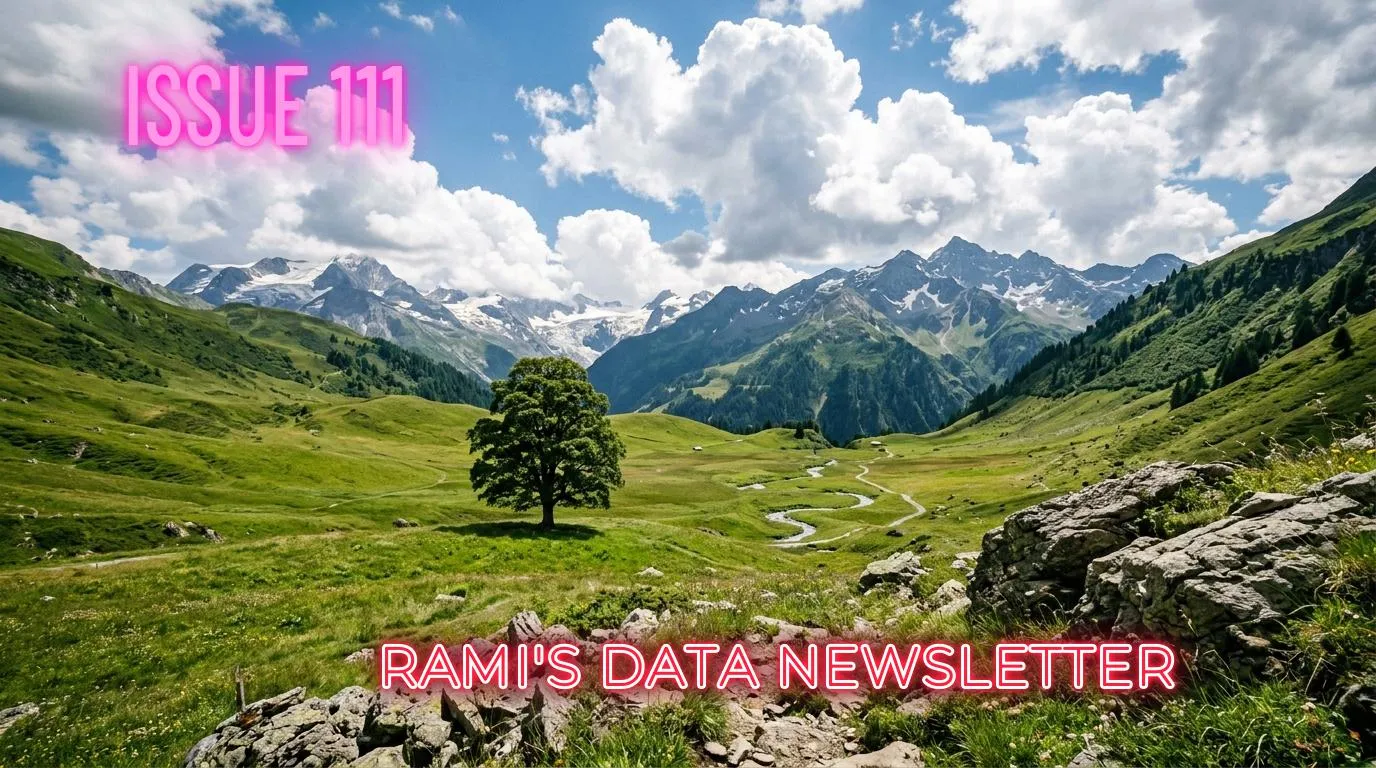
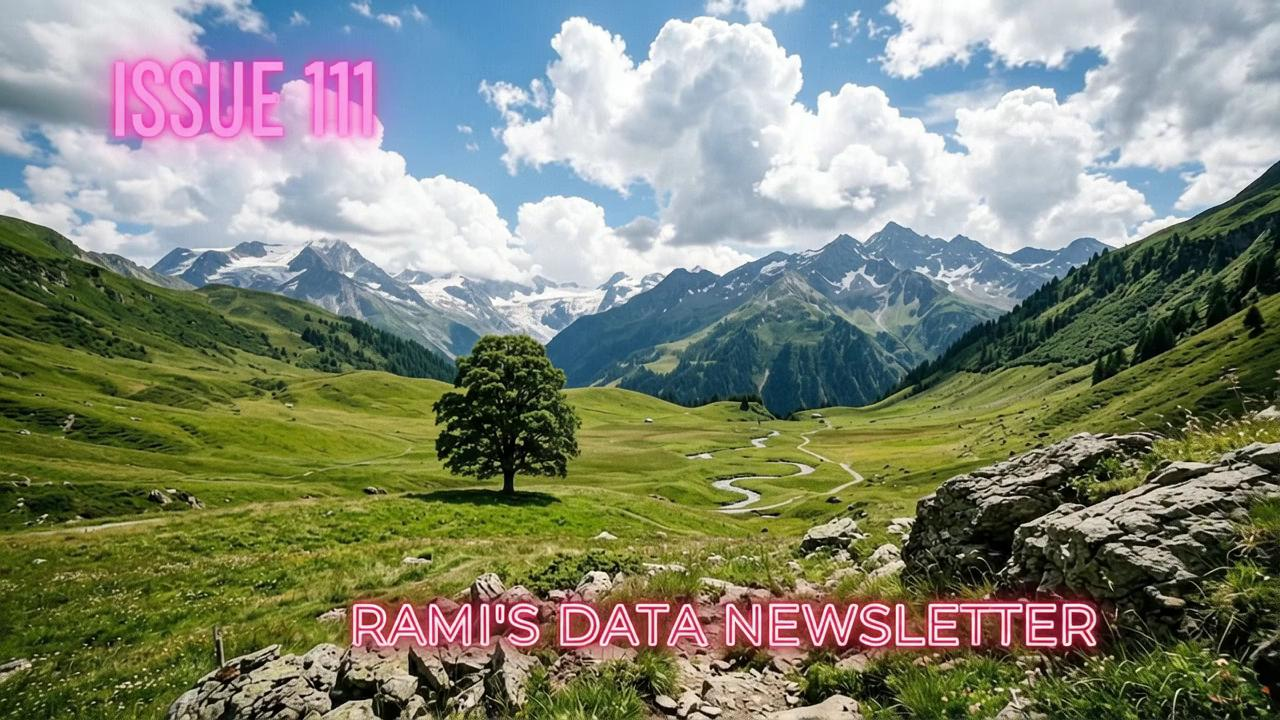

In [10]:
issues.select(issues.issue_label, issues.cover, issues.video).collect()

The clouds roll across and the camera drifts in toward the tree, while the words stay sharp and in place.

The picture is different every time a model makes it. Pixeltable stores this one with the issue.

## Issue 109 gets its own prompts, cover, and video

Issue 109's scene is a night sky in the style of Van Gogh, with a horse in a wheat field. It's the same insert with a new row, and the same cost, so I ran it before recording too.

In [11]:
issues.insert([row for row in ISSUES if row['issue_number'] == 109], on_error='ignore')

Inserted 1 row with 0 errors in 39.33 s (0.03 rows/s)


1 row inserted.

The insert says 1 row inserted. Pixeltable only computed the new row, and issue 111 kept its picture and its video.

issue_label,cover,video
ISSUE 109,,
ISSUE 111,,

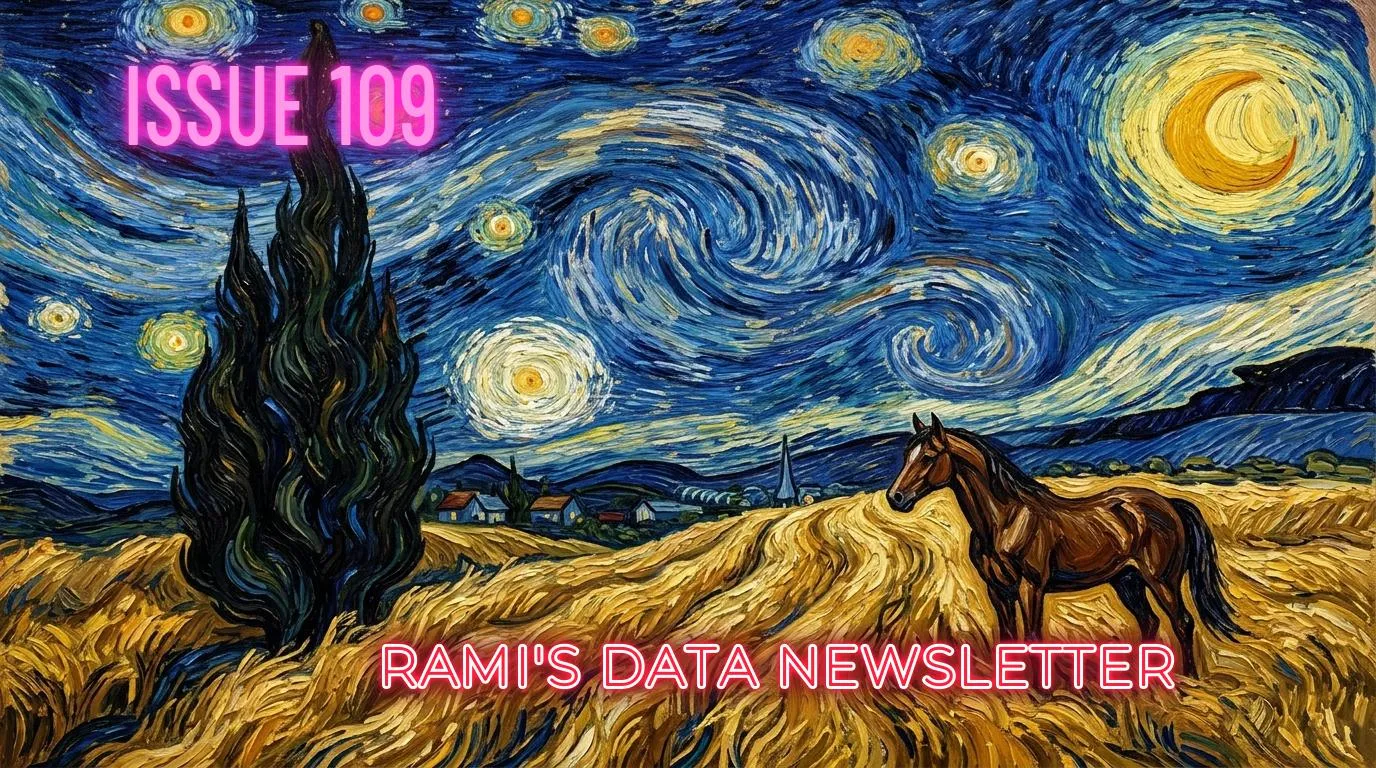
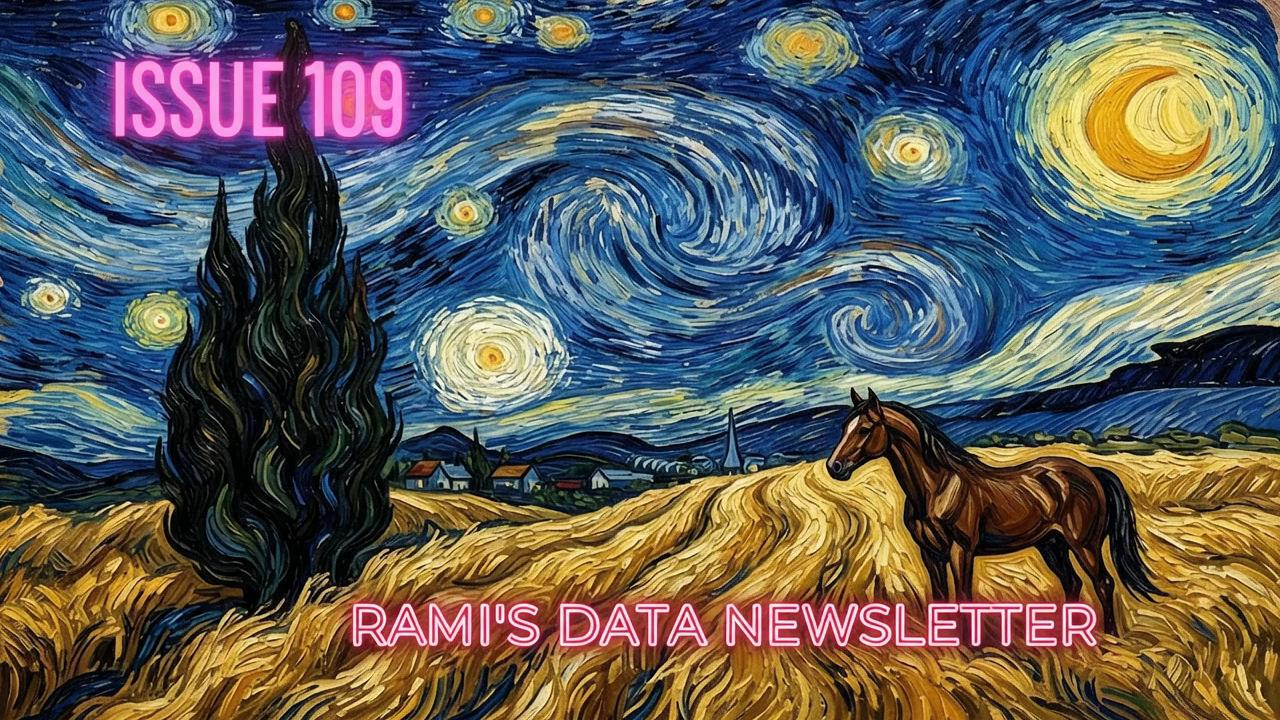
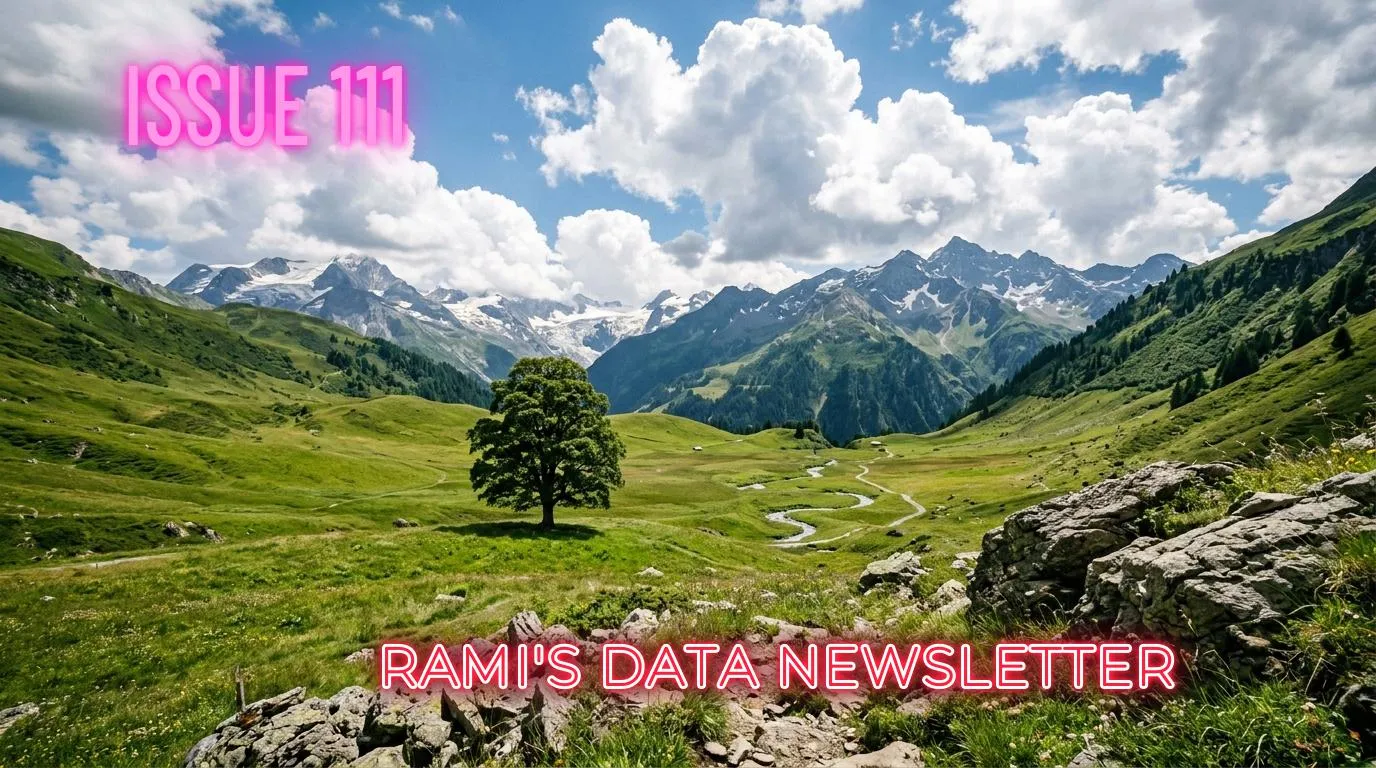
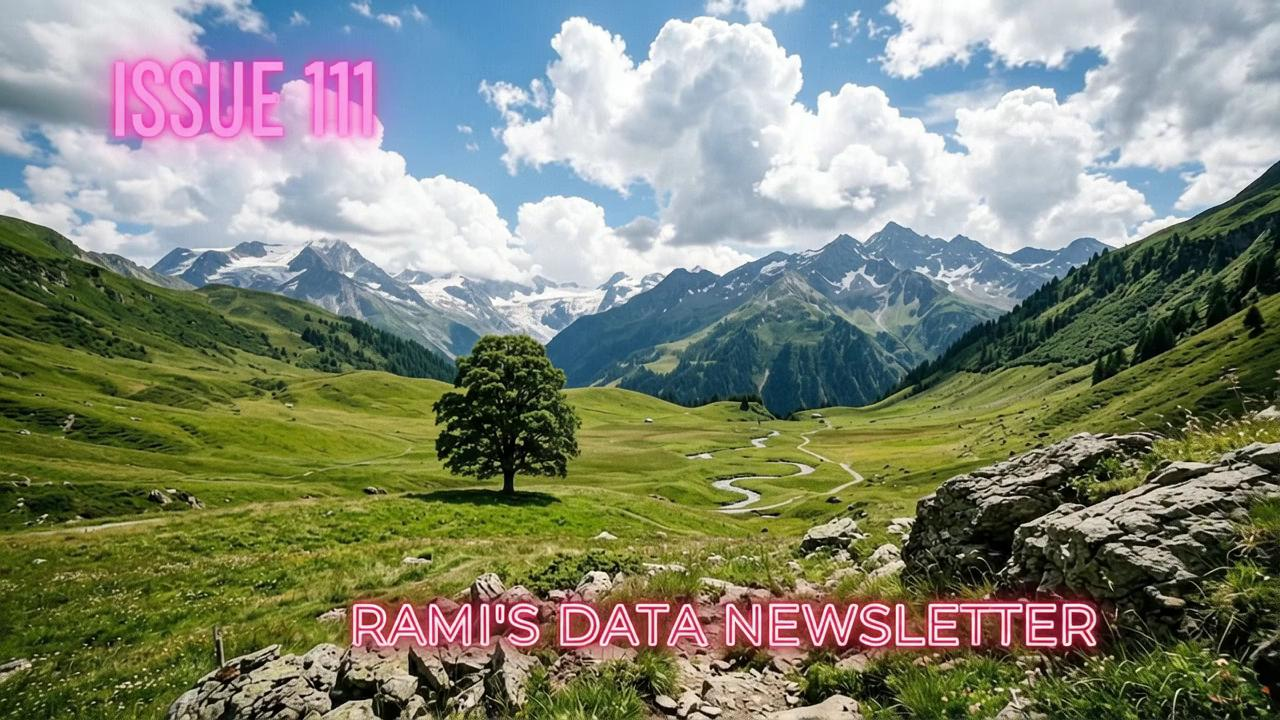

In [12]:
issues.select(issues.issue_label, issues.cover, issues.video).order_by(issues.issue_number).collect()

This video comes from its own scene: the sky swirls, the horse lifts its head, and the painting stays a painting.

`issue_number` is the primary key, so if you insert the same issue twice, you get an error instead of a second copy.

## When a video fails, rerun just that video

Omni sometimes stalls. When a call fails, the row keeps its picture and its cover, and the error sits in the `video` cell. Every computed column has `errortype` and `errormsg`, so we can list the rows that failed.

In [13]:
issues.where(issues.video.errortype != None).select(
    issues.issue_number, issues.video.errortype, issues.video.errormsg
).collect()

issue_number,video_errortype,video_errormsg


In this recording, the list is empty: both videos came through.

`recompute_columns` with `errors_only=True` calls Omni again for the failed rows only. The pictures and covers aren't made again, so you don't pay for them twice.

In [14]:
issues.recompute_columns('video', errors_only=True)

No rows affected.

After a rerun, list the failed rows again. An empty list means every issue has its video.

## One insert per issue, a cover and a video back

We typed a number and a scene for two issues, and each came back with a branded cover and a 5-second video. The README shows how to insert your own, with or without an inspiration image. To make the covers yours, change the newsletter's name in `udfs.py`.